## Using LSTM to analyze resting state networks

This notebook includes code to classify ADHD from healthy controls using LSTM model with rs-fMRI data.

First let's import the relevant libraries

In [21]:
# !pip install -r requirements_LSTM.txt
from nilearn import datasets
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
plt.style.use('ggplot')

#nilearn - neuroimaging tailored library
from nilearn.input_data import NiftiMapsMasker
from nilearn import plotting

#sklearn - basic ML tools
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from sklearn import metrics

#keras - for NN models
from keras.models import Model, Sequential
from keras.layers import Input, Dense
from keras.layers import LSTM
from keras import optimizers
from keras.utils import plot_model
from keras import utils
from keras.callbacks import EarlyStopping
from sklearn.metrics import roc_curve


#scipy- statistical analysis tools
from scipy.stats import ttest_1samp
#from scipy import interp



## Preparing data for analysis ##

Import data, and exctract features

In [22]:
## load the smith (ICA based) mask
## 'rsn10': 10 ICA maps from the above that matched across task and rest
# http://brainmap.org/pubs/SmithPNAS09.pdf

smith_atlas = datasets.fetch_atlas_smith_2009()
smith_atlas_rs_networks = smith_atlas.rsn70


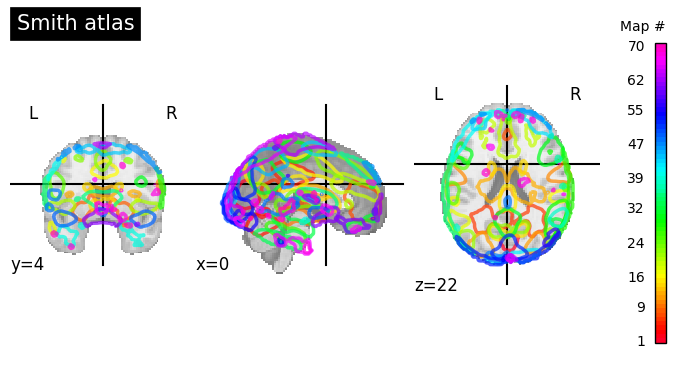

In [23]:
plotting.plot_prob_atlas(smith_atlas_rs_networks,
                         title='Smith atlas',
                         colorbar=True)
plotting.show()

In [24]:
# Import preprocessed, ready-to-go, datasets
adhd_data=datasets.fetch_adhd(n_subjects=50)

In [25]:
# exploring the header of one image
import nibabel as nib
img=nib.load(adhd_data['func'][0])

print(img.header['dim'])
print(img.header['pixdim'])


[  4  61  73  61 176   1   1   1]
[-1.  3.  3.  3.  2.  0.  0.  0.]


In [26]:
# Region signals extraction- exctract the values of the ten networks

masker = NiftiMapsMasker(maps_img=smith_atlas_rs_networks,  # Smith stals
                         standardize=True, # centers and norms the time-series
                         memory='nilearn_cache', # cache
                         verbose=0) #do not print verbose

In [27]:
all_subjects_data=[]
labels=[]  # 1 if ADHD, 0 if control

for func_file, confound_file, phenotypic in zip(
        adhd_data.func, adhd_data.confounds, adhd_data.phenotypic):

    time_series = masker.fit_transform(func_file, confounds=confound_file)

    all_subjects_data.append(time_series)
    labels.append(phenotypic['adhd'])


In [28]:
print('N control:' ,labels.count(0))
print('N adhd:' ,labels.count(1))

N control: 20
N adhd: 20


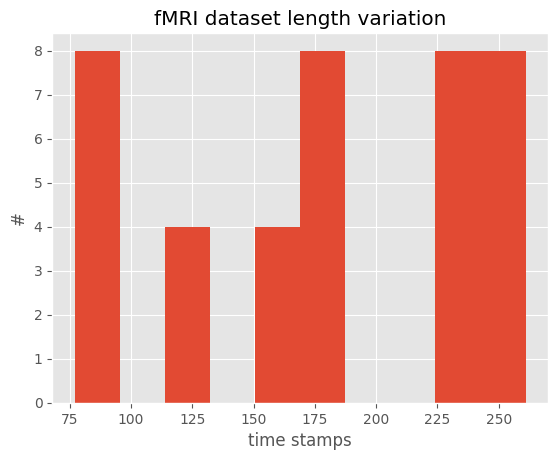

In [29]:
plt.hist([len(i) for i in all_subjects_data])
plt.title('fMRI dataset length variation')
plt.xlabel('time stamps')
plt.ylabel('#')
plt.show()

In [30]:
# find the longest image
max_len_image=np.max([len(i) for i in all_subjects_data])


In [31]:
# reshape

all_subjects_data_reshaped=[]
for subject_data in all_subjects_data:
  # Padding
  N= max_len_image-len(subject_data)
  padded_array=np.pad(subject_data, ((0, N), (0,0)),
                      'constant', constant_values=(0))
  subject_data=padded_array
  subject_data=np.array(subject_data)
  subject_data.reshape(subject_data.shape[0],subject_data.shape[1],1)
  all_subjects_data_reshaped.append(subject_data)


In [32]:
# shape of data

# 40 subjects
# 261 time stamps
# 10 netwroks values

np.array(all_subjects_data_reshaped).shape

(40, 261, 70)

In [33]:
# The data, split between train and test sets.

def get_train_test(X, y, i, verbrose=False):
  '''
  split to train and test and reshape data
  X data
  y labels
  i random state
  '''
  X_train, X_test, y_train, y_test = train_test_split(X,
                                        y, test_size=0.2, random_state=i)



  # Reshapes data to 4D for Hierarchical RNN.
  t_shape=np.array(all_subjects_data_reshaped).shape[1]
  RSN_shape=np.array(all_subjects_data_reshaped).shape[2]

  X_train = np.reshape(X_train, (len(X_train), t_shape, RSN_shape))
  X_test = np.reshape(X_test, (len(X_test), t_shape, RSN_shape))

  X_train = X_train.astype('float32')
  X_test = X_test.astype('float32')

  if verbrose:
    print(X_train.shape[0], 'train samples')
    print(X_test.shape[0], 'test samples')

  # Converts class vectors to binary class matrices.
  y_train = utils.to_categorical(y_train, 2)
  y_test = utils.to_categorical(y_test, 2)

  return X_train, X_test, y_train, y_test



## Build the LSTM model

In [34]:
# create the model

model = Sequential()

# LSTM layers -
# Long Short-Term Memory layer - Hochreiter 1997.
t_shape=np.array(all_subjects_data_reshaped).shape[1]
RSN_shape=np.array(all_subjects_data_reshaped).shape[2]

model.add(LSTM(units=70, # dimensionality of the output space
               dropout=0.4, # Fraction of the units to drop (inputs)
               recurrent_dropout=0.0, # Keep the fast GPU recurrent kernel enabled
               return_sequences=True, # return the last state in addition to the output
               input_shape=(t_shape,RSN_shape)))

model.add(LSTM(units=60,
               dropout=0.4,
               recurrent_dropout=0.0,
               return_sequences=True))

model.add(LSTM(units=50,
               dropout=0.4,
               recurrent_dropout=0.0,
               return_sequences=True))

model.add(LSTM(units=40,
               dropout=0.4,
               recurrent_dropout=0.0,
               return_sequences=False))


model.add(Dense(units=2,
                activation="sigmoid"))

model.compile(loss='binary_crossentropy',
                optimizer=optimizers.Adam(learning_rate=0.001),
                metrics=['binary_accuracy'])

print(model.summary())



Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_4 (LSTM)               (None, 261, 70)           39480     
                                                                 
 lstm_5 (LSTM)               (None, 261, 60)           31440     
                                                                 
 lstm_6 (LSTM)               (None, 261, 50)           22200     
                                                                 
 lstm_7 (LSTM)               (None, 40)                14560     
                                                                 
 dense_1 (Dense)             (None, 2)                 82        
                                                                 
Total params: 107762 (420.95 KB)
Trainable params: 107762 (420.95 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


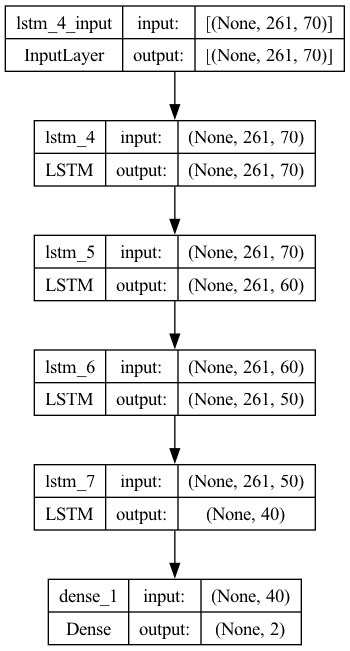

In [35]:
plot_model(model, show_shapes=True, show_layer_names=True)


## Train the LSTM model

32 train samples
8 test samples
Epoch 1/30


2026-11-03 15:47:51.001418: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:51.188677: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:51.236789: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:51.291877: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:51.344503: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:51.474286: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:51.543717: I tensorflow/core/grappler/optimizers/cust

1/1 [==============================] - ETA: 0s - loss: 0.6945 - binary_accuracy: 0.5000

2026-11-03 15:47:51.682014: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:51.953232: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:52.014096: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:52.048056: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:52.088372: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:52.126927: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 2s 2s/step - loss: 0.6945 - binary_accuracy: 0.5000 - val_loss: 0.6886 - val_binary_accuracy: 0.6429
Epoch 2/30
1/1 [==============================] - 0s 78ms/step - loss: 0.6902 - binary_accuracy: 0.6200 - val_loss: 0.6881 - val_binary_accuracy: 0.5714
Epoch 3/30
1/1 [==============================] - 0s 66ms/step - loss: 0.6887 - binary_accuracy: 0.6000 - val_loss: 0.6881 - val_binary_accuracy: 0.5714
Epoch 4/30
1/1 [==============================] - 0s 66ms/step - loss: 0.6874 - binary_accuracy: 0.6000 - val_loss: 0.6878 - val_binary_accuracy: 0.5714
Epoch 5/30
1/1 [==============================] - 0s 67ms/step - loss: 0.6828 - binary_accuracy: 0.6200 - val_loss: 0.6875 - val_binary_accuracy: 0.5714
Epoch 6/30
1/1 [==============================] - 0s 65ms/step - loss: 0.6783 - binary_accuracy: 0.6000 - val_loss: 0.6867 - val_binary_accuracy: 0.5714
Epoch 7/30
1/1 [==============================] - 0s 66ms/step - loss: 0.6716 - binary_accuracy

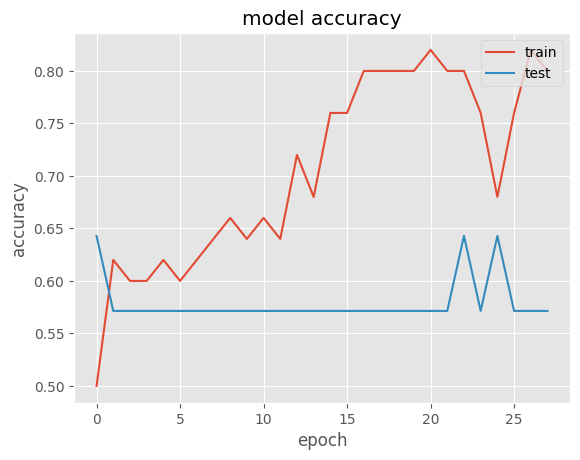

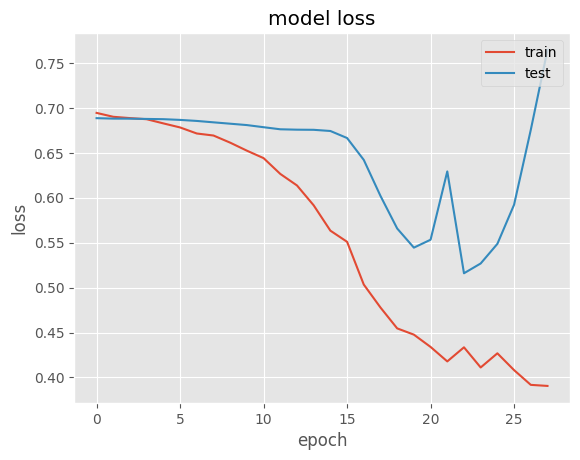

In [36]:
X_train, X_test, y_train, y_test = get_train_test(all_subjects_data_reshaped,
                                                    labels, i=8, verbrose=True)

early_stopping = EarlyStopping(monitor='val_loss', patience=5,
                               restore_best_weights=True)
history = model.fit(X_train, y_train, validation_split=0.2, epochs=30,
                    callbacks=[early_stopping])

# summarize history for accuracy
plt.plot(history.history['binary_accuracy'])
plt.plot(history.history['val_binary_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper right')
plt.show()

# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper right')
plt.show()


## Evaluate the LSTM model

In [37]:
from sklearn.metrics import accuracy_score

def boostrapping_hypothesis_testing(X_train, y_train, X_test, y_test,
                                    n_iterations=5, n_epochs=50):

  '''
  hypothesis testing function
  X_train, y_train, X_test, y_test- the data
  n_iterations- number of bootdtaping iterations
  n_epochs - number of epochs for model's training
  '''

  accuracy=[] ## model accuracy
  roc_msrmnts_fpr=[] ## false positive rate
  roc_msrmnts_tpr=[] ## true positive rate

  # run bootstrap
  for i in range(n_iterations):
    # prepare train and test sets
    X_train, X_test, y_train, y_test=get_train_test(all_subjects_data_reshaped,
                                              labels, i=i, verbrose=False)
    # fit model
    print('fitting..')
    model.fit(X_train, y_train, validation_split=0.2, epochs=n_epochs,
              callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                        restore_best_weights=True)])

    # evaluate model
    print('evaluating..')
    y_pred=model.predict(X_test)
    y_test_1d=[i[0] for i in y_test]
    y_pred_1d=[1.0 if i[0]>.5 else 0.0 for i in y_pred]

    fpr, tpr, _ = roc_curve(y_test_1d, y_pred_1d)

    acc_score = accuracy_score(y_test_1d, y_pred_1d)

    accuracy.append(acc_score)
    roc_msrmnts_fpr.append(fpr)
    roc_msrmnts_tpr.append(tpr)

  return accuracy, roc_msrmnts_fpr, roc_msrmnts_tpr



accuracy, roc_msrmnts_fpr, roc_msrmnts_tpr  = boostrapping_hypothesis_testing(X_train, y_train, X_test, y_test)

fitting..
Epoch 1/50
1/1 [==============================] - 0s 161ms/step - loss: 0.5464 - binary_accuracy: 0.5800 - val_loss: 0.2982 - val_binary_accuracy: 0.9286
Epoch 2/50
1/1 [==============================] - 0s 70ms/step - loss: 0.5176 - binary_accuracy: 0.6200 - val_loss: 0.3213 - val_binary_accuracy: 0.7143
Epoch 3/50
1/1 [==============================] - 0s 66ms/step - loss: 0.6118 - binary_accuracy: 0.6800 - val_loss: 0.3464 - val_binary_accuracy: 0.7143
Epoch 4/50
1/1 [==============================] - 0s 66ms/step - loss: 0.4952 - binary_accuracy: 0.7200 - val_loss: 0.3410 - val_binary_accuracy: 0.7143
Epoch 5/50
1/1 [==============================] - 0s 81ms/step - loss: 0.4907 - binary_accuracy: 0.6800 - val_loss: 0.3228 - val_binary_accuracy: 0.8571
Epoch 6/50
1/1 [==============================] - 0s 71ms/step - loss: 0.4591 - binary_accuracy: 0.7600 - val_loss: 0.3076 - val_binary_accuracy: 0.8571
evaluating..


2026-11-03 15:47:54.892090: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:54.944911: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:54.981687: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:55.024869: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-11-03 15:47:55.061472: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 0s 397ms/step
fitting..
Epoch 1/50
1/1 [==============================] - 0s 101ms/step - loss: 0.4493 - binary_accuracy: 0.6400 - val_loss: 0.3962 - val_binary_accuracy: 0.8571
Epoch 2/50
1/1 [==============================] - 0s 71ms/step - loss: 0.5131 - binary_accuracy: 0.6200 - val_loss: 0.4114 - val_binary_accuracy: 0.8571
Epoch 3/50
1/1 [==============================] - 0s 69ms/step - loss: 0.4203 - binary_accuracy: 0.7200 - val_loss: 0.4376 - val_binary_accuracy: 0.6429
Epoch 4/50
1/1 [==============================] - 0s 69ms/step - loss: 0.3974 - binary_accuracy: 0.8200 - val_loss: 0.4243 - val_binary_accuracy: 0.7143
Epoch 5/50
1/1 [==============================] - 0s 70ms/step - loss: 0.4070 - binary_accuracy: 0.8000 - val_loss: 0.3697 - val_binary_accuracy: 0.7857
Epoch 6/50
1/1 [==============================] - 0s 70ms/step - loss: 0.3275 - binary_accuracy: 0.8400 - val_loss: 0.3525 - val_binary_accuracy: 0.7143
Epoch 7/50
1/1 [==

In [38]:
#def calc_p_val(stats, h0, n_iterations):
def calc_p_val(stats, h0):
  '''
  finds the p value for the results

  '''
  # calc pval
  tset, pval = ttest_1samp(stats, h0)

  return pval

p_val=calc_p_val(accuracy, .5)

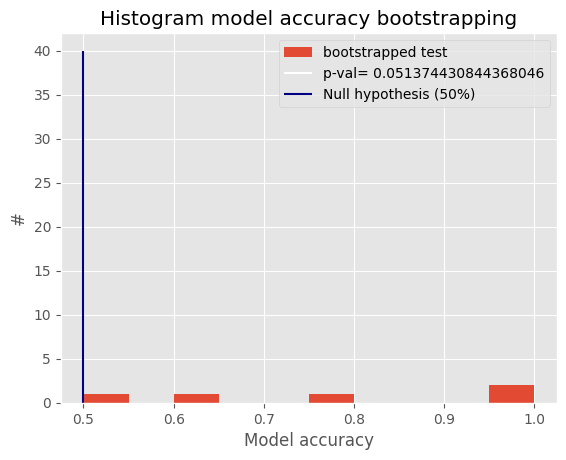

In [39]:
def plot_p_value(stats, p_val):
  '''
  plots the bootstrapping results with the null hypothesis value
  '''

  plt.hist(stats, label='bootstrapped test')
  plt.vlines(.5, 0, 40, color='white', label='p-val= {}'.format(p_val))
  plt.vlines(.5, 0, 40, color='navy', label='Null hypothesis (50%)')

  plt.title('Histogram model accuracy bootstrapping')
  plt.xlabel('Model accuracy')
  plt.ylabel('#')
  plt.legend()
  plt.plot()

plot_p_value(accuracy, p_val)

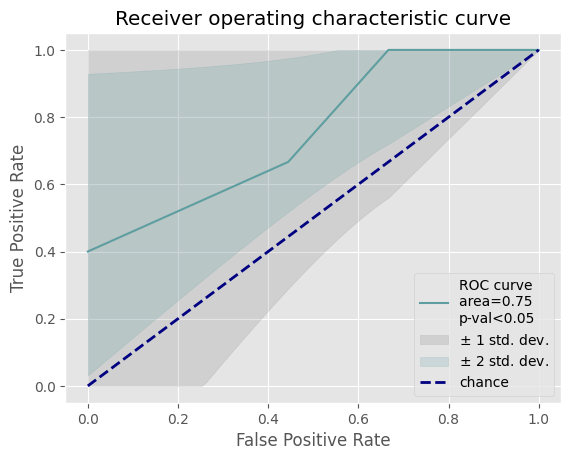

In [40]:
def plot_roc_curve(fpr_vals, tpr_vals, roc_auc, p_val):
  '''
  This function plots the median value of the roc for the boostrapped
    results calculated above.

  fpr stand for false-positive rate
  tpr stands for true-positive rate
  roc_auc is the area under curve
  '''

  ## get the values
  N=len(fpr_vals)
  tprs=[]
  median_fpr=np.linspace(0, 1, 100)
#  tprs=[interp(median_fpr, fpr_vals[i], tpr_vals[i]) for i in range(N)]
  tprs=[np.interp(median_fpr, fpr_vals[i], tpr_vals[i]) for i in range(N)]
  std_tpr = np.std(tprs, axis=0)

  mean_tpr = np.mean(tprs, axis=0)
  median_tpr=np.median(tprs, axis=0)
  median_tpr[-1] = 1.0

  tprs_upper_2 = np.minimum(mean_tpr + 2*std_tpr, 1)
  tprs_lower_2 = np.maximum(mean_tpr - 2*std_tpr, 0)

  tprs_upper_1 = np.minimum(mean_tpr + std_tpr, 1)
  tprs_lower_1 = np.maximum(mean_tpr - std_tpr, 0)

  median_auc_roc=np.median(roc_auc)


  ## plot
  if p_val<0.05:
    p_val=0.05
  plt.plot(median_fpr, median_tpr, color='cadetblue',
           label='ROC curve \narea={} \np-val<{}'.\
            format(np.round(median_auc_roc,2),
                   np.round(p_val,2)))
  plt.fill_between(median_fpr, tprs_lower_2, tprs_upper_2, color='grey', alpha=.2,
                 label=r'$\pm$ 1 std. dev.')

  plt.fill_between(median_fpr, tprs_lower_1, tprs_upper_1, color='cadetblue', alpha=.2,
                 label=r'$\pm$ 2 std. dev.')

  plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label=r'chance')

  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('Receiver operating characteristic curve')
  plt.legend(loc="lower right")

  plt.show()



plot_roc_curve(roc_msrmnts_fpr, roc_msrmnts_tpr, accuracy,p_val)